# Figure S-TSS-regression: class effect and coverage footprint per TSS

No_deep cohort, Griffin difference z-scored within each sample (14,221 TSSs). One ordinary least-squares fit per TSS: value ~ class, and value ~ class + covariates.

- a, b: class t adjusted for the confounders (mean coverage (log10), plasma volume, age, sex) against unadjusted;
- c, d: the same, adjusted for all covariates (confounders plus mean fragment length, mean fragment GC, cfDNA concentration (log10)); a tumour moves these three, so this is a lower bound on the class effect;
- e: number of TSSs with a significant class effect (BH q < 0.05) per adjustment;
- f, g: dip depth against coverage per sample, pan-cancer task: (f) mean raw Griffin difference over the TSSs; (g) correlation of the sample's standardised TSS vector with the mean vector of the panel of normals.

The first cell asserts pinned values (TSS counts, correlations, weight shares) and fails if a rerun moves them.

Source data in `data/no_deep/`: `figS10_tss_regression_{summary,tss,samples}.csv`, written by `COHORT_VARIANT=no_deep python src/figures/export/export_figS10_tss_regression.py`; also `fig3_baseline_scalars.csv`, `fig4_baseline_scalars.csv`, `figS17_tss_effects_{task}.csv`. Writes `output/no_deep/figS_tss_regression.png` and `.pdf`. Run from `src/figures/`.

In [1]:
import os

if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))
os.makedirs("output/no_deep", exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy import stats
from scipy.stats import spearmanr

summ = pd.read_csv("data/no_deep/figS10_tss_regression_summary.csv")
tss = pd.read_csv("data/no_deep/figS10_tss_regression_tss.csv")
TASKS = {"brca_crc": "BRCA/CRC", "pancan": "Pan-cancer"}
MODELS = {"confounders": "adjusted for confounders", "all": "adjusted for all covariates"}
SCALARS = {"brca_crc": "fig3_baseline_scalars.csv", "pancan": "fig4_baseline_scalars.csv"}


def S(task, model, term="class"):
    r = summ[(summ["task"] == task) & (summ["scope"] == "pooled") & (summ["model"] == model) & (summ["term"] == term)]
    assert len(r) == 1, (task, model, term)
    return r.iloc[0]


# pinned values; a rerun that moves them fails here
for task, (n0, rho, slope, n1, cov, cov_rho) in {"brca_crc": (100, 0.960, 1.020, 244, 404, -0.173),
                                                 "pancan": (343, 0.987, 0.993, 394, 1237, -0.197)}.items():
    assert int(S(task, "unadjusted")["n_sig_q05"]) == n0
    c = S(task, "confounders")
    assert abs(c["spearman_t_vs_unadjusted"] - rho) < 0.002 and abs(c["slope_t_vs_unadjusted"] - slope) < 0.002
    assert int(c["n_sig_q05"]) == n1 and int(c["n_sign_flips_among_sig"]) == 0
    k = S(task, "confounders", "mean_coverage")
    assert int(k["n_sig_q05"]) == cov and abs(k["spearman_t_vs_class_unadjusted"] - cov_rho) < 0.002
    d = tss[tss["task"] == task]
    assert abs(spearmanr(d["t_mean_coverage_confounders"], d["t_class_unadj"], nan_policy="omit")[0] - cov_rho) < 0.002
    sc = pd.read_csv(f"data/no_deep/{SCALARS[task]}")
    print(TASKS[task], "median coverage healthy / cancer:", sc.groupby("y_true")["mean_coverage"].median().round(2).tolist())
# the coverage footprint against the model's weights
COV = {}
for task, (n_cov, w_share, rho_w, n_both, n_class) in {"brca_crc": (404, 0.026, -0.015, 6, 100), "pancan": (1237, 0.079, 0.006, 21, 343)}.items():
    a = tss[tss["task"] == task]
    b = pd.read_csv(f"data/no_deep/figS17_tss_effects_{task}.csv")
    m = a.merge(b, left_on="tss_window_index", right_on="bed_row", suffixes=("", "_b"))
    assert len(m) == 14221 and (m["gene_name"] == m["gene"]).all()
    tc = m["t_mean_coverage_confounders"]
    n = int(S(task, "confounders", "mean_coverage")["n_samples"])
    sig = stats.false_discovery_control(2 * stats.t.sf(np.abs(tc), n - 6)) < 0.05
    w = m["weight_mean"].abs()
    COV[task] = dict(n_sig=int(sig.sum()), weight_share=w[sig].sum() / w.sum(), tss_share=sig.mean(),
                     rho_weight=spearmanr(tc, m["weight_mean"])[0], both=int(((m["q_class_unadj"] < 0.05) & sig).sum()))
    assert COV[task]["n_sig"] == n_cov and abs(COV[task]["weight_share"] - w_share) < 0.001
    assert abs(COV[task]["rho_weight"] - rho_w) < 0.002 and COV[task]["both"] == n_both
    assert int((m["q_class_unadj"] < 0.05).sum()) == n_class
print(pd.DataFrame(COV).T.round(3).to_string())

# dip depth against coverage, per sample
samples = pd.read_csv("data/no_deep/figS10_tss_regression_samples.csv")
DIP_ALL = {}
for task in TASKS:
    x = pd.read_csv(f"data/no_deep/{SCALARS[task]}")[["sample_id", "mean_coverage"]].merge(samples, on="sample_id")
    assert len(x) == {"brca_crc": 244, "pancan": 367}[task]
    DIP_ALL[task] = x
    rho = {col: [spearmanr(x.loc[x["y_true"] == k, "mean_coverage"], x.loc[x["y_true"] == k, col])[0] for k in (0, 1)]
           for col in ("raw_mean_griffin_diff", "raw_sd_griffin_diff", "profile_r_griffin_diff")}
    tv = {}
    for name, X in [("class", np.column_stack([np.ones(len(x)), x["y_true"]])),
                    ("class + coverage", np.column_stack([np.ones(len(x)), x["y_true"], np.log10(x["mean_coverage"])]))]:
        y_ = x["profile_r_griffin_diff"].to_numpy()
        inv = np.linalg.inv(X.T @ X); b = inv @ X.T @ y_
        tv[name] = b[1] / np.sqrt(inv[1, 1] * ((y_ - X @ b) ** 2).sum() / (len(y_) - X.shape[1]))
    print(TASKS[task], {k: np.round(v, 2).tolist() for k, v in rho.items()}, "| dip pattern, class t:", {k: round(v, 2) for k, v in tv.items()},
          "| mean dip depth, median healthy / cancer:", x.groupby("y_true")["raw_mean_griffin_diff"].median().round(3).tolist(),
          "p", float(f"{stats.mannwhitneyu(x.loc[x['y_true'] == 1, 'raw_mean_griffin_diff'], x.loc[x['y_true'] == 0, 'raw_mean_griffin_diff']).pvalue:.2g}"))
    pin = {"brca_crc": ((-0.06, 0.00), (-0.86, -0.85), (0.87, 0.75), (-1.59, -4.25)), "pancan": ((-0.06, 0.07), (-0.86, -0.79), (0.87, 0.73), (-2.68, -5.33))}[task]
    assert np.allclose(rho["raw_mean_griffin_diff"], pin[0], atol=0.006) and np.allclose(rho["raw_sd_griffin_diff"], pin[1], atol=0.006)
    assert np.allclose(rho["profile_r_griffin_diff"], pin[2], atol=0.006)
    assert np.allclose([tv["class"], tv["class + coverage"]], pin[3], atol=0.006)
# samples far below the healthy trend of dip pattern on coverage (quadratic in log10 coverage, 3 healthy SD)
for task, (n_flat, n_h) in {"brca_crc": (16, 0), "pancan": (37, 0)}.items():
    x = DIP_ALL[task]
    h_ = x[x["y_true"] == 0]
    res = x["profile_r_griffin_diff"] - np.polyval(np.polyfit(np.log10(h_["mean_coverage"]), h_["profile_r_griffin_diff"], 2), np.log10(x["mean_coverage"]))
    z = res / res[x["y_true"] == 0].std()
    assert int((z[x["y_true"] == 1] < -3).sum()) == n_flat and int((z[x["y_true"] == 0] < -3).sum()) == n_h
    rest = z[(x["y_true"] == 1) & (z >= -3)]
    print(TASKS[task], f"cancers below the trend: {n_flat} of {int((x['y_true'] == 1).sum())}; healthy {n_h} of {len(h_)}; the other cancers vs healthy, Mann-Whitney p {stats.mannwhitneyu(rest, z[x['y_true'] == 0]).pvalue:.2f}")
DIP = DIP_ALL["pancan"]
DIP_RHO = {col: [spearmanr(DIP.loc[DIP["y_true"] == k, "mean_coverage"], DIP.loc[DIP["y_true"] == k, col])[0] for k in (0, 1)]
           for col in ("raw_mean_griffin_diff", "profile_r_griffin_diff")}
rows = [dict(task=TASKS[t], model=m, term=x, n_sig=int(S(t, m, x)["n_sig_q05"]), pct=round(100 * S(t, m, x)["frac_sig_q05"], 2))
        for t in TASKS for m in MODELS for x in summ[(summ["model"] == m) & (summ["scope"] == "pooled")]["term"].unique()]
pd.DataFrame(rows).pivot_table(index=["model", "term"], columns="task", values=["n_sig", "pct"], sort=False)

BRCA/CRC median coverage healthy / cancer: [2.32, 2.57]
Pan-cancer median coverage healthy / cancer: [2.32, 2.52]


           n_sig  weight_share  tss_share  rho_weight  both
brca_crc   404.0         0.026      0.028      -0.015   6.0
pancan    1237.0         0.079      0.087       0.006  21.0
BRCA/CRC {'raw_mean_griffin_diff': [-0.06, 0.0], 'raw_sd_griffin_diff': [-0.86, -0.85], 'profile_r_griffin_diff': [0.87, 0.75]} | dip pattern, class t: {'class': np.float64(-1.59), 'class + coverage': np.float64(-4.25)} | mean dip depth, median healthy / cancer: [0.193, 0.184] p 0.00021
Pan-cancer {'raw_mean_griffin_diff': [-0.06, 0.07], 'raw_sd_griffin_diff': [-0.86, -0.79], 'profile_r_griffin_diff': [0.87, 0.73]} | dip pattern, class t: {'class': np.float64(-2.68), 'class + coverage': np.float64(-5.33)} | mean dip depth, median healthy / cancer: [0.193, 0.185] p 0.00019
BRCA/CRC cancers below the trend: 16 of 80; healthy 0 of 164; the other cancers vs healthy, Mann-Whitney p 0.54
Pan-cancer cancers below the trend: 37 of 203; healthy 0 of 164; the other cancers vs healthy, Mann-Whitney p 0.13


n_sig                 pct           
task                             BRCA/CRC Pan-cancer BRCA/CRC Pan-cancer
model       term                                                        
confounders class                   244.0      394.0     1.72       2.77
            mean_coverage           404.0     1237.0     2.84       8.70
            plasma_volume             6.0        0.0     0.04       0.00
            age                       0.0        0.0     0.00       0.00
            sex_female                0.0        0.0     0.00       0.00
all         class                    24.0      316.0     0.17       2.22
            mean_coverage           324.0      756.0     2.28       5.32
            plasma_volume             0.0        0.0     0.00       0.00
            age                       0.0        0.0     0.00       0.00
            sex_female                0.0        0.0     0.00       0.00
            fragment_length_mean     12.0       95.0     0.08       0.67
            mean_gc                  11.0       31.0     0.08       0.22
            cfdna_extracted           2.0       30.0     0.01       0.21

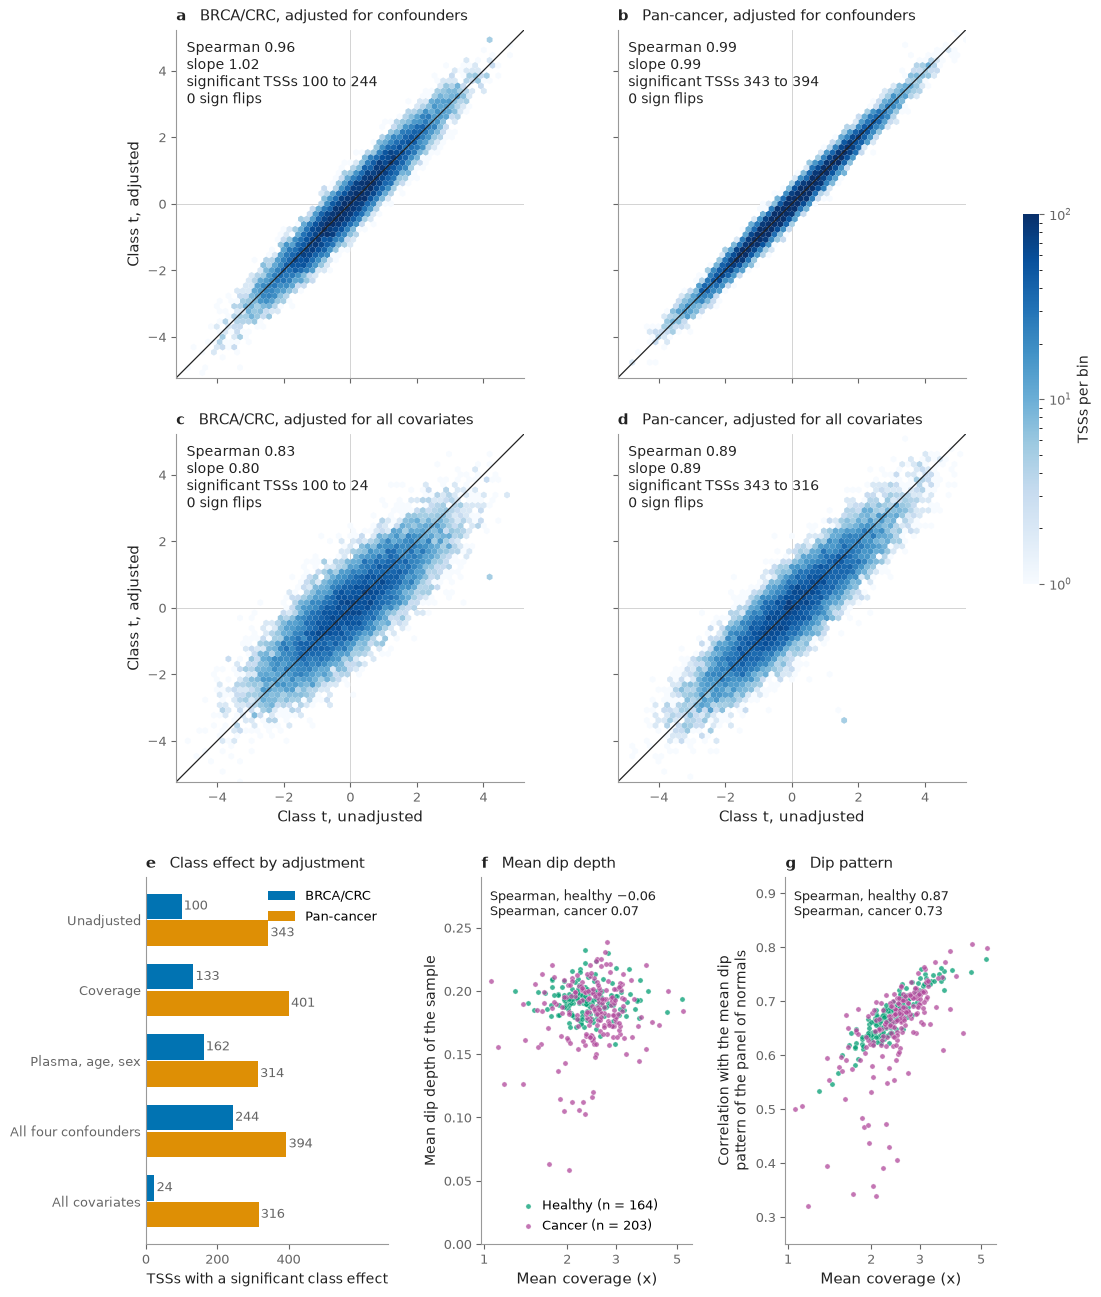

In [2]:
INK, MUTED = "#222222", "#666666"
TASK_COLORS = {"brca_crc": "#0173B2", "pancan": "#DE8F05"}
CLASS_COLORS = {"Healthy": "#029E73", "Cancer": "#B0489B"}
norm = LogNorm(vmin=1, vmax=100)
lim = float(np.nanpercentile(np.abs(tss[["t_class_unadj", "t_class_confounders", "t_class_all"]].to_numpy()), 99.98)) * 1.05


def style(ax):
    ax.tick_params(colors=MUTED, labelsize=9.5)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("0.6")


def ttl(ax, letter, text):
    ax.set_title(f"$\\mathbf{{{letter}}}$   {text}", loc="left", fontsize=10.5, color=INK)


fig = plt.figure(figsize=(10.5, 13.2))
outer = fig.add_gridspec(2, 1, height_ratios=[2.05, 1], hspace=0.17, left=0.08, right=0.89, top=0.97, bottom=0.05)
top = outer[0].subgridspec(2, 2, wspace=0.08, hspace=0.16)
bottom = outer[1].subgridspec(1, 3, wspace=0.42, width_ratios=[1.15, 1, 1])
# --- a-d: class t, adjusted against unadjusted -------------------------------------------------------
for r, (model, mlabel) in enumerate(MODELS.items()):
    for c, (task, tlabel) in enumerate(TASKS.items()):
        ax = fig.add_subplot(top[r, c])
        d = tss[tss["task"] == task]
        hb = ax.hexbin(d["t_class_unadj"], d[f"t_class_{model}"], gridsize=60, extent=(-lim, lim, -lim, lim),
                       norm=norm, mincnt=1, cmap="Blues", linewidths=0)
        ax.plot([-lim, lim], [-lim, lim], color=INK, linewidth=0.9)
        ax.axhline(0, color="0.8", linewidth=0.6, zorder=0); ax.axvline(0, color="0.8", linewidth=0.6, zorder=0)
        s0, s1 = S(task, "unadjusted"), S(task, model)
        ax.text(0.03, 0.97, f"Spearman {s1['spearman_t_vs_unadjusted']:.2f}\nslope {s1['slope_t_vs_unadjusted']:.2f}\n"
                            f"significant TSSs {int(s0['n_sig_q05'])} to {int(s1['n_sig_q05'])}\n"
                            f"{int(s1['n_sign_flips_among_sig'])} sign flips",
                transform=ax.transAxes, va="top", fontsize=10, color=INK)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
        style(ax)
        ttl(ax, "abcd"[2 * r + c], f"{tlabel}, {mlabel}")
        if r == 1:
            ax.set_xlabel("Class t, unadjusted", fontsize=10.5, color=INK)
        else:
            ax.tick_params(labelbottom=False)
        if c == 0:
            ax.set_ylabel("Class t, adjusted", fontsize=10.5, color=INK)
        else:
            ax.tick_params(labelleft=False)
# --- e: class-significant TSSs by adjustment ---------------------------------------------------------
ADJ = {"unadjusted": "Unadjusted", "coverage_only": "Coverage", "no_coverage": "Plasma, age, sex",
       "confounders": "All four confounders", "all": "All covariates"}
ax = fig.add_subplot(bottom[0])
y = np.arange(len(ADJ))[::-1]
h = 0.36
for j, (task, tlabel) in enumerate(TASKS.items()):
    vals = [int(S(task, m)["n_sig_q05"]) for m in ADJ]
    pos = y + (h / 2 + 0.01) * (1 if j == 0 else -1)
    ax.barh(pos, vals, height=h, color=TASK_COLORS[task], label=tlabel)
    for p, v in zip(pos, vals):
        ax.text(v + 6, p, f"{v}", va="center", fontsize=9, color=MUTED)
ax.set_yticks(y); ax.set_yticklabels(list(ADJ.values()), fontsize=10, color=INK)
ax.set_xlim(0, 680); ax.set_xticks([0, 200, 400])
ax.set_xlabel("TSSs with a significant class effect", fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=9.5, loc="upper right")
style(ax); ax.tick_params(axis="y", length=0)
ttl(ax, "e", "Class effect by adjustment")
# --- f, g: dip depth against coverage, pan-cancer task (it holds all BRCA/CRC samples) -------------------
mn = lambda v: f"{v:.2f}".replace("-", "−")
for c, (col, ylab, letter, tt) in enumerate([("raw_mean_griffin_diff", "Mean dip depth of the sample", "f", "Mean dip depth"),
                                             ("profile_r_griffin_diff", "Correlation with the mean dip\npattern of the panel of normals", "g", "Dip pattern")]):
    ax = fig.add_subplot(bottom[c + 1])
    for yv, lab in [(0, "Healthy"), (1, "Cancer")]:
        d = DIP[DIP["y_true"] == yv]
        ax.scatter(d["mean_coverage"], d[col], s=14, color=CLASS_COLORS[lab], alpha=0.75, edgecolors="white", linewidths=0.3,
                   label=f"{lab} (n = {len(d)})", zorder=2 if yv else 1)
    ax.set_xscale("log"); ax.set_xticks([1, 2, 3, 5]); ax.set_xticklabels(["1", "2", "3", "5"]); ax.minorticks_off()
    ax.set_xlabel("Mean coverage (x)", fontsize=10.5, color=INK)
    ax.set_ylabel(ylab, fontsize=10, color=INK)
    r = DIP_RHO[col]
    ax.text(0.04, 0.97, f"Spearman, healthy {mn(r[0])}\nSpearman, cancer {mn(r[1])}", transform=ax.transAxes, va="top", fontsize=9, color=INK)
    ax.set_ylim({"f": (0.0, 0.29), "g": (0.25, 0.93)}[letter])
    style(ax)
    ttl(ax, letter, tt)
    if c == 0:
        ax.legend(frameon=False, fontsize=9, loc="lower center", handletextpad=0.1)
cax = fig.add_axes([0.915, 0.55, 0.016, 0.28])
cb = fig.colorbar(hb, cax=cax)
cb.set_label("TSSs per bin", fontsize=10, color=INK)
cb.ax.tick_params(colors=MUTED, labelsize=9)
cb.outline.set_visible(False)
fig.savefig("output/no_deep/figS_tss_regression.png", dpi=300, bbox_inches="tight")
fig.savefig("output/no_deep/figS_tss_regression.pdf", bbox_inches="tight")
plt.show()